--- 1. AŞAMA: KEŞİFSEL VERİ ANALİZİ (EDA) ---

Veri Setinin Genel Yapısı:
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Router1  2000 non-null   int64
 1   Router2  2000 non-null   int64
 2   Router3  2000 non-null   int64
 3   Router4  2000 non-null   int64
 4   Router5  2000 non-null   int64
 5   Router6  2000 non-null   int64
 6   Router7  2000 non-null   int64
 7   Room     2000 non-null   int64
dtypes: int64(8)
memory usage: 125.1 KB

Eksik Veri Kontrolü:
 Router1    0
Router2    0
Router3    0
Router4    0
Router5    0
Router6    0
Router7    0
Room       0
dtype: int64

Sınıf (Oda) Dağılımı:
 Room
1    500
2    500
3    500
4    500
Name: count, dtype: int64


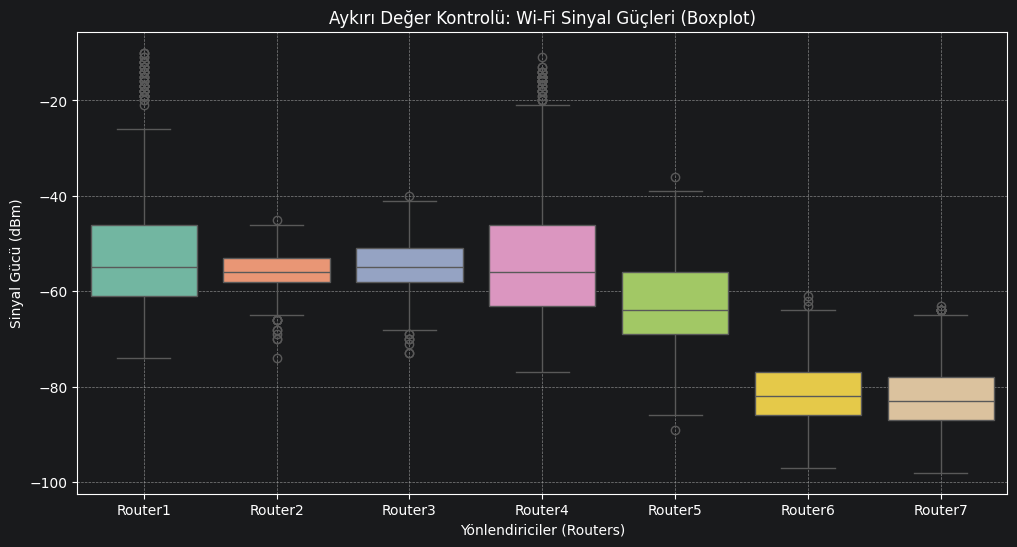

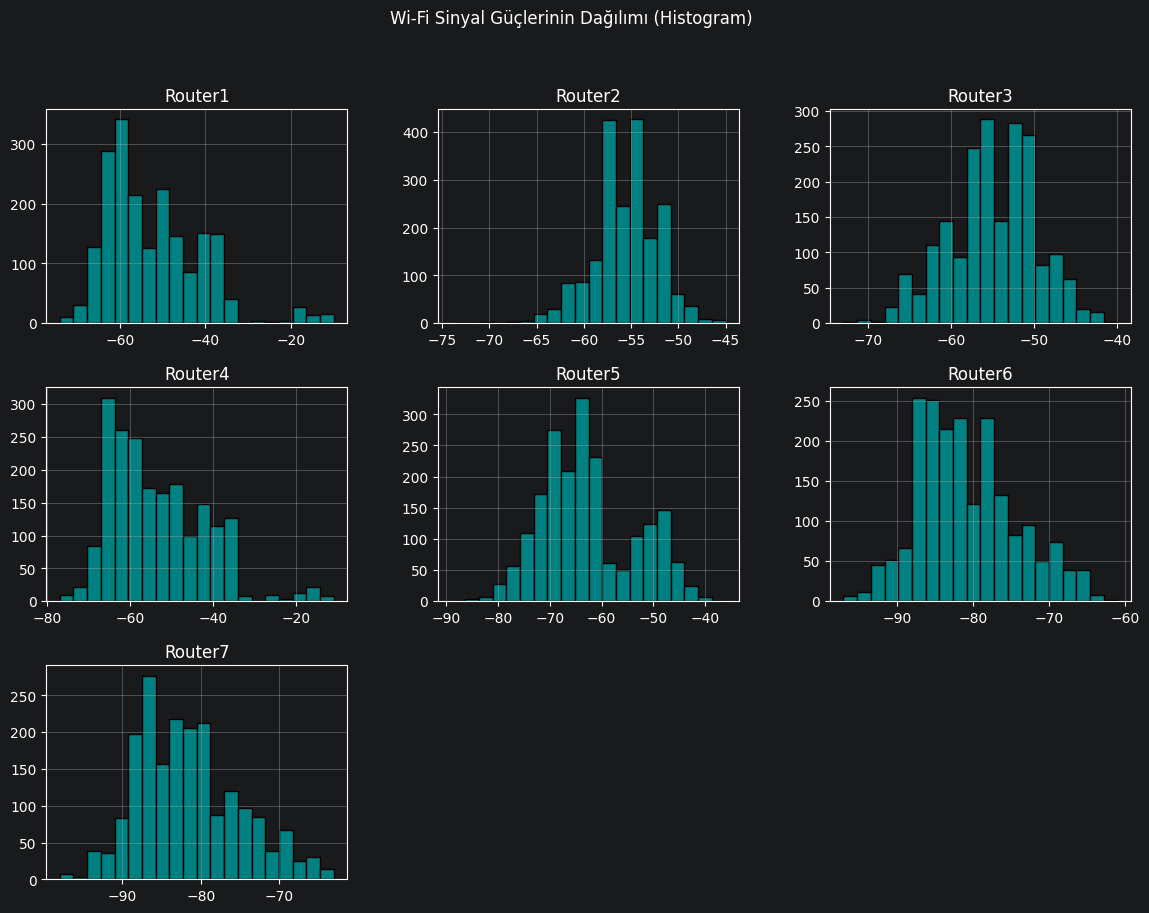

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

warnings.filterwarnings('ignore')

print("--- 1. AŞAMA: KEŞİFSEL VERİ ANALİZİ (EDA) ---")
column_names = ['Router1', 'Router2', 'Router3', 'Router4', 'Router5', 'Router6', 'Router7', 'Room']
df = pd.read_csv('wifi_localization.txt', sep='\t', names=column_names)

print("\nVeri Setinin Genel Yapısı:")
df.info()

print("\nEksik Veri Kontrolü:\n", df.isnull().sum())
print("\nSınıf (Oda) Dağılımı:\n", df['Room'].value_counts())

# Aykırı Değer Tespiti İçin Kutu Grafikleri (Boxplot)
plt.figure(figsize=(12, 6))
sns.boxplot(data=df.drop('Room', axis=1), palette="Set2")
plt.title("Aykırı Değer Kontrolü: Wi-Fi Sinyal Güçleri (Boxplot)")
plt.ylabel("Sinyal Gücü (dBm)")
plt.xlabel("Yönlendiriciler (Routers)")
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

# Veri Dağılımı İçin Histogramlar
df.drop('Room', axis=1).hist(bins=20, figsize=(14, 10), color='teal', edgecolor='black')
plt.suptitle("Wi-Fi Sinyal Güçlerinin Dağılımı (Histogram)")
plt.show()

In [3]:
print("--- 2. AŞAMA: VERİ ÖN İŞLEME ---")

# IQR Yöntemi ile Aykırı Değerleri Sınırlandırma (Capping)
def cap_outliers_iqr(dataframe, col):
    Q1 = dataframe[col].quantile(0.25)
    Q3 = dataframe[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    dataframe[col] = np.where(dataframe[col] < lower_bound, lower_bound, dataframe[col])
    dataframe[col] = np.where(dataframe[col] > upper_bound, upper_bound, dataframe[col])
    return dataframe

df_clean = df.copy()
for col in df_clean.columns[:-1]:
    df_clean = cap_outliers_iqr(df_clean, col)

# Özellikler (X) ve Hedef Sınıf (y) Ayırımı
X = df_clean.drop('Room', axis=1)
y = df_clean['Room']

# Veriyi Eğitim (%80) ve Test (%20) Olarak Bölme
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# StandardScaler ile Tüm Sinyal Değerlerini Aynı Ölçeğe Getirme
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Aykırı değerler IQR ile baskılandı ve StandardScaler ile ölçeklendirildi.")
print(f"Eğitim verisi: {X_train_scaled.shape}, Test verisi: {X_test_scaled.shape}")

--- 2. AŞAMA: VERİ ÖN İŞLEME ---
Aykırı değerler IQR ile baskılandı ve StandardScaler ile ölçeklendirildi.
Eğitim verisi: (1600, 7), Test verisi: (400, 7)


In [4]:
print("--- 3. AŞAMA: ÇOKLU MODEL EĞİTİMİ ---")

# Değerlendirilecek algoritmaların tanımlanması
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "K-Nearest Neighbors (KNN)": KNeighborsClassifier(n_neighbors=5),
    "Support Vector Machine (SVC)": SVC(kernel='rbf', random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

print("Modeller başarıyla tanımlandı ve eğitime hazır.")

--- 3. AŞAMA: ÇOKLU MODEL EĞİTİMİ ---
Modeller başarıyla tanımlandı ve eğitime hazır.


In [5]:
print("--- 4. AŞAMA: MODEL KARŞILAŞTIRMA ---")
results = []

# Döngü içerisinde modellerin test edilmesi ve doğruluk (accuracy) hesaplaması
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    results.append({"Model Adı": name, "Doğruluk Oranı": round(acc, 4)})

# Sonuçların Tablo Haline Getirilip Raporlanması
df_results = pd.DataFrame(results).sort_values(by="Doğruluk Oranı", ascending=False).reset_index(drop=True)
print("\n", df_results.to_string())

--- 4. AŞAMA: MODEL KARŞILAŞTIRMA ---

                       Model Adı  Doğruluk Oranı
0     K-Nearest Neighbors (KNN)          0.9850
1                 Random Forest          0.9825
2           Logistic Regression          0.9800
3  Support Vector Machine (SVC)          0.9775
4                 Decision Tree          0.9725
5             Gradient Boosting          0.9725


--- 5. AŞAMA: HİPERPARAMETRE OPTİMİZASYONU ---
Bulunan En İyi SVM Parametreleri: {'C': 1, 'gamma': 0.1}

--- NİHAİ MODEL SONUÇLARI ---
Ulaşılan En Yüksek Doğruluk Skoru: 0.9825

Detaylı Sınıflandırma Raporu (Precision, Recall, F1-Score):
               precision    recall  f1-score   support

           1       0.99      0.99      0.99       100
           2       0.98      0.98      0.98       100
           3       0.96      0.98      0.97       100
           4       1.00      0.98      0.99       100

    accuracy                           0.98       400
   macro avg       0.98      0.98      0.98       400
weighted avg       0.98      0.98      0.98       400



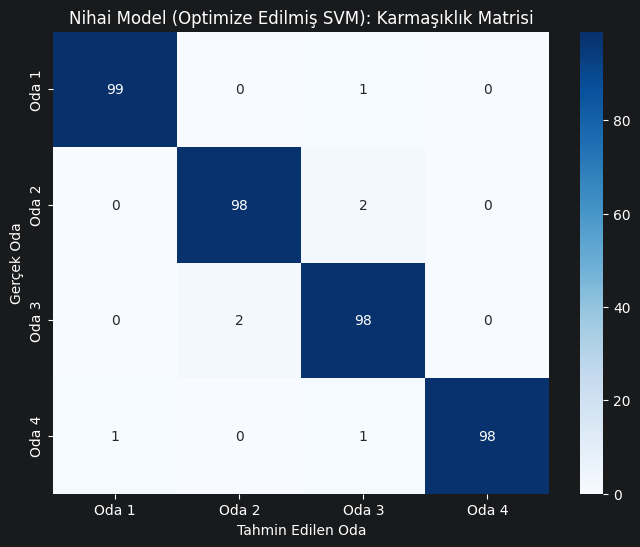

In [6]:
print("--- 5. AŞAMA: HİPERPARAMETRE OPTİMİZASYONU ---")

# Tablodan en yüksek potansiyele sahip olan SVM modeli seçilip optimize ediliyor.
svm_param_grid = {
    'C': [0.1, 1, 10, 100],            # Hata tolerans parametresi
    'gamma': ['scale', 'auto', 0.1, 1] # Karar sınırlarının esnekliği
}

# GridSearchCV Kurulumu ve Çalıştırılması
grid_search = GridSearchCV(SVC(kernel='rbf', random_state=42), svm_param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train_scaled, y_train)

best_svm_model = grid_search.best_estimator_
print("Bulunan En İyi SVM Parametreleri:", grid_search.best_params_)

# Optimize Edilmiş Son Model İle Test İşleminin Tekrarlanması
y_pred_best = best_svm_model.predict(X_test_scaled)

print("\n--- NİHAİ MODEL SONUÇLARI ---")
print("Ulaşılan En Yüksek Doğruluk Skoru:", round(accuracy_score(y_test, y_pred_best), 4))
print("\nDetaylı Sınıflandırma Raporu (Precision, Recall, F1-Score):\n", classification_report(y_test, y_pred_best))

# En Başarılı Modelin Karmaşıklık Matrisi (Confusion Matrix) Çizimi
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred_best)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Oda 1', 'Oda 2', 'Oda 3', 'Oda 4'],
            yticklabels=['Oda 1', 'Oda 2', 'Oda 3', 'Oda 4'])
plt.title("Nihai Model (Optimize Edilmiş SVM): Karmaşıklık Matrisi")
plt.xlabel("Tahmin Edilen Oda")
plt.ylabel("Gerçek Oda")
plt.show()